### Problem 14 : Noise and Error Mitigation

Every result in this repo so far has been computed on a **perfect** simulator. Real quantum
hardware is not perfect, and the gap is not small - it is the reason quantum computers are not yet
useful for most of the things we would like to do with them.

Back in Problem 7 the closing task was *"introduce noise to this system and check how it deviates
from the ideal predicted values"*. This notebook is that task, done properly.

**TASK :**
1. Build a realistic noise model and watch a Bell state fall apart.
2. Fix the **measurement** errors with a calibration matrix.
3. Fix part of the **gate** errors with zero-noise extrapolation.
4. Put it all together on the SWAP test from Problem 7.

#### The three things that go wrong

| Error type | What happens | Typical size today |
|---|---|---|
| **Gate error** | Each gate is applied slightly wrong | ~0.1% for 1-qubit, ~0.5-3% for 2-qubit gates |
| **Readout error** | The measurement reports the wrong bit | ~1-5% per qubit |
| **Decoherence (T1/T2)** | The qubit leaks its state to the environment over time | limits circuit depth |

Two-qubit gates are the expensive ones - roughly an order of magnitude worse than single-qubit
gates. That single fact drives most of quantum circuit design.

#### Mitigation is not correction

**Quantum error correction** encodes one logical qubit into many physical ones and removes errors
outright. It needs thousands of physical qubits per logical qubit - it is the long game.

**Quantum error mitigation** does not remove errors. It runs *noisy* circuits and then
post-processes the results to estimate what the noiseless answer would have been. It is cheap,
it works today, and it is what everyone actually uses. That is our subject here.

In [1]:
import numpy as np
import itertools
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

#### Building a noise model

Aer lets us attach errors to specific gate names.

- `depolarizing_error(p, n)` : with probability p, throw away the state of those n qubits and
  replace it with something completely random. It is the simplest "average" error channel.
- `ReadoutError([[P(0|0), P(1|0)], [P(0|1), P(1|1)]])` : the classical confusion matrix of the
  detector. Notice the asymmetry below - on real superconducting hardware ∣1⟩ decays towards ∣0⟩
  during the measurement, so misreading a 1 as a 0 is more likely than the reverse.

In [2]:
def build_noise_model(readout=True):
    """A rough imitation of a present-day superconducting device."""
    nm = NoiseModel()

    # 1-qubit gates: 0.5% depolarizing
    nm.add_all_qubit_quantum_error(
        depolarizing_error(0.005, 1), ['u', 'rx', 'ry', 'rz', 'h', 'x', 'sx']
    )
    # 2-qubit gates: 3% depolarizing - much worse, as on real hardware
    nm.add_all_qubit_quantum_error(
        depolarizing_error(0.03, 2), ['cx', 'cz']
    )
    # readout: P(read 1 | prepared 0) = 5%,  P(read 0 | prepared 1) = 8%
    if readout:
        nm.add_all_qubit_readout_error(ReadoutError([[0.95, 0.05], [0.08, 0.92]]))

    return nm


noise_model = build_noise_model()
ideal_sim = AerSimulator()
noisy_sim = AerSimulator(noise_model=noise_model)

print(noise_model)

NoiseModel:
  Basis gates: ['cx', 'cz', 'h', 'id', 'rx', 'ry', 'rz', 'sx', 'u', 'x']
  Instructions with noise: ['rx', 'sx', 'x', 'ry', 'rz', 'measure', 'cx', 'h', 'u', 'cz']
  All-qubits errors: ['u', 'rx', 'ry', 'rz', 'h', 'x', 'sx', 'cx', 'cz', 'measure']


#### Part 1 : a Bell state under noise

Problem 3 gave us a perfect ∣00⟩ + ∣11⟩. Let us run exactly that circuit on the noisy backend.
The outcomes `01` and `10` are **impossible** for a Bell state, so every count in those bins is
pure error - a very convenient built-in error meter.

In [3]:
shots = 8192

bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
bell.measure([0, 1], [0, 1])

counts_ideal = ideal_sim.run(transpile(bell, ideal_sim), shots=shots).result().get_counts()
counts_noisy = noisy_sim.run(transpile(bell, noisy_sim), shots=shots).result().get_counts()

print("Ideal:", counts_ideal)
print("Noisy:", counts_noisy)

error_rate = (counts_noisy.get('01', 0) + counts_noisy.get('10', 0)) / shots
print(f"\nImpossible outcomes ('01' and '10'): {error_rate * 100:.1f}% of all shots")

Ideal: {'11': 4029, '00': 4163}
Noisy: {'01': 545, '10': 564, '00': 3698, '11': 3385}

Impossible outcomes ('01' and '10'): 13.5% of all shots


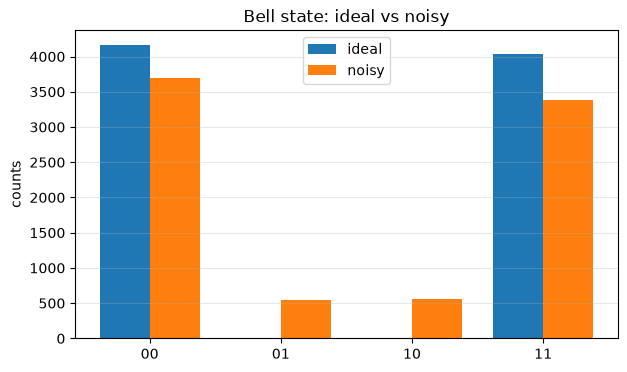

In [4]:
labels = ['00', '01', '10', '11']
width = 0.38
pos = np.arange(len(labels))

plt.figure(figsize=(7, 4))
plt.bar(pos - width/2, [counts_ideal.get(l, 0) for l in labels], width, label='ideal')
plt.bar(pos + width/2, [counts_noisy.get(l, 0) for l in labels], width, label='noisy')
plt.xticks(pos, labels); plt.ylabel("counts")
plt.title("Bell state: ideal vs noisy")
plt.legend(); plt.grid(axis='y', alpha=0.3); plt.show()

#### Part 2 : Measurement error mitigation

Readout error is the easiest error to undo, because it is **classical**. The detector has a fixed
confusion matrix M :

**M[i, j] = P( we read bitstring i ∣ the state really was j )**

We can measure M directly : prepare each basis state ∣00⟩, ∣01⟩, ∣10⟩, ∣11⟩ in turn (just X gates,
then measure) and record what comes back. Those 2ⁿ experiments are the **calibration circuits**.

Then, since our observed distribution is **v_noisy = M · v_true**, we simply solve the linear system

**v_true = M⁻¹ · v_noisy**

The catch : the number of calibration circuits is 2ⁿ, so this exact approach only scales to a
handful of qubits. Real deployments use tensored or sparse approximations of M - but the idea is
identical.

In [5]:
def calibration_matrix(n_qubits, backend, shots=8192):
    """Measure M[i, j] = P(read i | prepared j) by preparing every basis state."""
    basis = [''.join(b) for b in itertools.product('01', repeat=n_qubits)]
    M = np.zeros((2 ** n_qubits, 2 ** n_qubits))

    for j, prepared in enumerate(basis):
        qc = QuantumCircuit(n_qubits, n_qubits)
        # Qiskit prints the most significant qubit first, so reverse when preparing
        for wire, bit in enumerate(reversed(prepared)):
            if bit == '1':
                qc.x(wire)
        qc.measure(range(n_qubits), range(n_qubits))

        counts = backend.run(transpile(qc, backend), shots=shots).result().get_counts()
        for i, observed in enumerate(basis):
            M[i, j] = counts.get(observed, 0) / shots

    return M, basis


M, basis = calibration_matrix(2, noisy_sim)
print("Calibration matrix (columns = prepared state, rows = what we read):")
print(np.round(M, 3))
print("\nThe diagonal is the probability of reading correctly:", np.round(np.diag(M), 3))

Calibration matrix (columns = prepared state, rows = what we read):
[[0.901 0.076 0.077 0.007]
 [0.049 0.876 0.004 0.077]
 [0.047 0.003 0.872 0.075]
 [0.002 0.044 0.046 0.841]]

The diagonal is the probability of reading correctly: [0.901 0.876 0.872 0.841]


In [6]:
def mitigate(counts, M, basis, shots):
    """Undo the readout error: v_true = M^-1 . v_noisy"""
    v_noisy = np.array([counts.get(b, 0) / shots for b in basis])
    v_true = np.linalg.solve(M, v_noisy)
    return dict(zip(basis, v_true))


raw = {b: counts_noisy.get(b, 0) / shots for b in basis}
fixed = mitigate(counts_noisy, M, basis, shots)

print(f"{'state':>6} {'ideal':>9} {'noisy':>9} {'mitigated':>11}")
for b in basis:
    print(f"{b:>6} {counts_ideal.get(b, 0)/shots:9.3f} {raw[b]:9.3f} {fixed[b]:11.3f}")

err_raw = raw['01'] + raw['10']
err_fix = fixed['01'] + fixed['10']
print(f"\nImpossible-outcome weight: {err_raw*100:.1f}%  ->  {err_fix*100:.1f}% after mitigation")

 state     ideal     noisy   mitigated
    00     0.508     0.451       0.496
    01     0.000     0.067       0.005
    10     0.000     0.069       0.010
    11     0.492     0.413       0.489

Impossible-outcome weight: 13.5%  ->  1.5% after mitigation


A large chunk of the damage disappears - and it cost us four extra calibration circuits, not a
single extra qubit.

Two honest caveats you should know :
- The residual error is **gate** error (that 3% depolarizing CNOT), which readout mitigation cannot
  touch. That is what Part 3 is for.
- `M⁻¹` is not a probability-preserving operation, so mitigated values can come out slightly
  **negative**. Production tools solve a constrained least-squares problem instead of inverting.

#### Part 3 : Zero-Noise Extrapolation (ZNE)

Gate errors cannot be inverted with a calibration matrix - they are quantum, not classical. ZNE
takes a wonderfully sneaky approach instead :

> We cannot turn the noise **down**. But we can turn it **up** - deliberately, by a known factor.
> Measure the answer at several noise levels, then extrapolate the curve back to **zero noise**.

How do we amplify the noise on purpose? **Unitary folding**. Since U†U = I, replacing the circuit U
with

**U → U (U† U)^k**

leaves the ideal result completely unchanged while multiplying the gate count - and therefore the
error - by (2k + 1). So we sample noise scale factors 1, 3, 5, … and fit.

In [7]:
def fold(circuit, k):
    """U -> U (U^dagger U)^k  : same ideal result, (2k+1) times the gates."""
    folded = circuit.copy()
    for _ in range(k):
        folded = folded.compose(circuit.inverse()).compose(circuit)
    return folded


# The SWAP test from Problem 7, as a gate-only circuit (measurement added later)
def swap_test_body(x_a, x_b):
    qc = QuantumCircuit(3)
    qc.h(0)
    qc.ry(2 * x_a, 1)
    qc.ry(2 * x_b, 2)
    qc.cswap(0, 1, 2)
    qc.h(0)
    # decompose into 1- and 2-qubit gates so the noise model actually applies to it
    return transpile(qc, basis_gates=['u', 'cx'], optimization_level=1)


body = swap_test_body(0.35, 0.2)
print("Gates in the unfolded circuit:", dict(body.count_ops()))
print("Gates after folding once     :", dict(fold(body, 1).count_ops()))

Gates in the unfolded circuit: {'u': 12, 'cx': 8}
Gates after folding once     : {'u': 36, 'cx': 24}


> ⚠️ **The trap that catches everyone.** When you send the folded circuit to the backend you must
> pass `optimization_level=0`. Otherwise the transpiler notices the U†U pairs, helpfully cancels
> them all, and hands back the original circuit - your noise scaling silently does nothing and the
> extrapolation returns garbage. If your ZNE "works" but the depths do not grow, this is why.

In [8]:
# For this part we drop the readout error, so that what remains is purely gate noise
gate_only_sim = AerSimulator(noise_model=build_noise_model(readout=False))


def swap_test_fidelity(x_a, x_b, k, backend, shots=60000):
    """Estimate |<a|b>|^2 with the noise amplified by a factor of (2k+1)."""
    qc = QuantumCircuit(3, 1)
    qc.compose(fold(swap_test_body(x_a, x_b), k), inplace=True)
    qc.measure(0, 0)

    tqc = transpile(qc, backend, optimization_level=0)     # <- do NOT let it cancel the folds
    counts = backend.run(tqc, shots=shots).result().get_counts()
    return 2 * counts.get('0', 0) / shots - 1, tqc.depth()


x_a, x_b = 0.35, 0.2
exact = np.cos(x_a - x_b) ** 2

scales, values = [], []
for k in (0, 1, 2):
    value, depth = swap_test_fidelity(x_a, x_b, k, gate_only_sim)
    scales.append(2 * k + 1)
    values.append(value)
    print(f"noise scale {2*k+1} | circuit depth {depth:3d} | fidelity estimate {value:.4f}")

print(f"\nExact answer: {exact:.4f}")

noise scale 1 | circuit depth  15 | fidelity estimate 0.7901
noise scale 3 | circuit depth  43 | fidelity estimate 0.5058
noise scale 5 | circuit depth  71 | fidelity estimate 0.3213

Exact answer: 0.9777


In [9]:
# Extrapolate back to zero noise
scales_arr = np.array(scales, dtype=float)
values_arr = np.array(values, dtype=float)

# (a) linear fit - the standard first choice
linear = np.polyval(np.polyfit(scales_arr, values_arr, 1), 0.0)

# (b) exponential fit - depolarizing noise decays as exp(-lambda * scale), so fit a line to log(y)
log_fit = np.polyfit(scales_arr, np.log(values_arr), 1)
exponential = np.exp(np.polyval(log_fit, 0.0))

print(f"Unmitigated (scale 1) : {values[0]:.4f}   error {abs(values[0] - exact):.4f}")
print(f"ZNE, linear fit       : {linear:.4f}   error {abs(linear - exact):.4f}")
print(f"ZNE, exponential fit  : {exponential:.4f}   error {abs(exponential - exact):.4f}")
print(f"Exact                 : {exact:.4f}")

Unmitigated (scale 1) : 0.7901   error 0.1875
ZNE, linear fit       : 0.8907   error 0.0870
ZNE, exponential fit  : 0.9907   error 0.0130
Exact                 : 0.9777


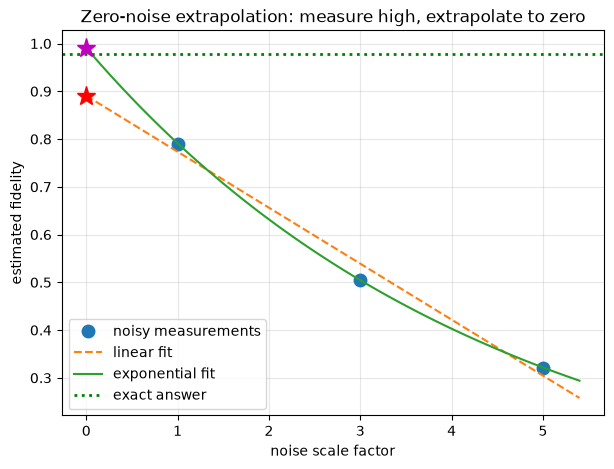

In [10]:
grid = np.linspace(0, 5.4, 100)

plt.figure(figsize=(7, 5))
plt.plot(scales_arr, values_arr, 'o', markersize=9, label='noisy measurements')
plt.plot(grid, np.polyval(np.polyfit(scales_arr, values_arr, 1), grid), '--', label='linear fit')
plt.plot(grid, np.exp(np.polyval(log_fit, grid)), '-', label='exponential fit')
plt.axhline(exact, color='g', linestyle=':', linewidth=2, label='exact answer')
plt.plot(0, linear, 'r*', markersize=14)
plt.plot(0, exponential, 'm*', markersize=14)

plt.xlabel("noise scale factor"); plt.ylabel("estimated fidelity")
plt.title("Zero-noise extrapolation: measure high, extrapolate to zero")
plt.legend(); plt.grid(alpha=0.3); plt.show()

#### OUTCOME :

The exponential fit lands almost exactly on the true value, and even the crude linear fit halves the
error. That is not a coincidence : **depolarizing noise decays exponentially with circuit depth**,
so an exponential model matches the physics. Choosing the extrapolation function that matches your
device's dominant error channel is most of the skill in ZNE.

And note the price. Three noise levels meant running the circuit three times over, at up to five
times the depth. Mitigation buys accuracy with **runtime**, and the cost grows steeply as the noise
gets worse. This trade is the central economics of the NISQ era.

#### The toolbox

| Technique | Fixes | Cost | Notes |
|---|---|---|---|
| **Readout / measurement mitigation** | classical detector errors | 2ⁿ calibration circuits | cheap, big win, always do it |
| **Zero-noise extrapolation** | gate errors, on expectation values | 3-5x the circuit runs | works on any observable |
| **Probabilistic error cancellation** | gate errors, in principle exactly | exponential sampling overhead | needs full device tomography |
| **Dynamical decoupling** | idle-qubit decoherence | free - just fills gaps with pulses | for circuits with idle time |
| **Error correction** | everything, properly | thousands of physical qubits | the long-term answer |

#### Why this matters for Quantum AI

Go back and look at Problem 12 with noisy eyes. Barren plateaus said gradients shrink exponentially
with qubit count; noise says every expectation value carries an error floor. Together they squeeze
trainable models from both sides - the signal falls while the noise floor stays put. Anyone
claiming a quantum advantage in machine learning has to survive **both** effects, which is exactly
why honest classical baselines (Problem 9.2) matter so much.

#### Key Takeaways :
- Two-qubit gates dominate your error budget - minimise them.
- Readout error is classical and largely invertible with a calibration matrix.
- ZNE amplifies noise on purpose and extrapolates back to zero; match the fit to the physics.
- Always transpile folded circuits with `optimization_level=0`.
- Mitigation trades **runtime** for **accuracy**; it does not remove errors.

#### TASK :
1. Sweep the 2-qubit gate error from 0.1% to 10% and plot the Bell-state error rate against it.
   How steeply does it climb?
2. Run the full Problem 7 QNN classifier under this noise model. Do the ties and the classifications
   still come out right, and how does the shot-noise tolerance need to change?
3. Add scale factors 7 and 9 to the ZNE fit. Does more data help, or does the extra depth make the
   high-noise points too unreliable to be worth fitting?
4. Combine both techniques : put the readout error back in, apply the calibration matrix to every
   folded circuit's counts, then extrapolate. How close to exact can you get?